This notebook reformats JADES fits files and creates a photometry table of all the candidate sources in each observed filter which can be used to create a CMD in the cmd.ipynb notebook.

Dependencies:
* numpy
* pandas
* matplotlib
* astropy
* scipy

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob

import astropy
from astropy.table import Table
from astropy.io import fits
from astropy.visualization import ZScaleInterval, ImageNormalize, LinearStretch, LogStretch, PowerStretch
from astropy.wcs import WCS

import matplotlib.pyplot as plt
from matplotlib import patheffects
from matplotlib.ticker import ScalarFormatter, FuncFormatter, LogLocator

from scipy.stats import gaussian_kde

## Create photometry csv file from a set of spaceKLIP companion ecsv files

In [2]:
idirNC = '/Users/ebruinsma/Desktop/projects/hip65426/data_nircam/'
sources = ['b', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c8', 'c9', 'c10', 'c11', 'c12']

dfs = []

for source in sources:
    print(source)

    folderNC = idirNC + f"companions_july2026/{source}/KL40/C1/*.ecsv"
    files = glob.glob(folderNC)

    source_df = None

    for tab in sorted(files):
        t = Table.read(tab, format="ascii.ecsv")
        df = t.to_pandas()
    
        # reset index to avoid duplicate index issues
        df = df.reset_index(drop=True)
    
        # extract filter label from filename
        filt = df['FILTER'].iloc[0]
        #print(filt)
    
        # prefix columns so they are unique
        df.columns = [f"{c}_{filt}" for c in df.columns]
    
        if source_df is None:
            source_df = df
        else:
            source_df = pd.concat([source_df, df], axis=1)
    
    # also reset index before appending
    source_df = source_df.reset_index(drop=True)
    source_df.insert(0, "Source", source)
    #print(source)
    
    dfs.append(source_df)

mega_df = pd.concat(dfs, ignore_index=True)
mega_df
mega_df.to_csv("photometry.csv", index=False)


b
c1
c2
c3
c4
c5
c6
c8
c9
c10
c11
c12


## reformat JADES fits files 
You can download relevant files from: 
* You can download the JADES DR5 files here: https://slate.ucsc.edu/~brant/jades-dr5/
* There are various extensions in the fits file. For this tutorial, we use the KRON since it captures total integrated flux for extended or low-redshift sources.

In [3]:
tab = Table.read("hlsp_jades_jwst_nircam_goods-s_photometry_v5.0_catalog.fits", hdu="KRON_CONV")
hdul = fits.open("hlsp_jades_jwst_nircam_goods-s_photometry_v5.0_catalog.fits") 
hdul.info()

Filename: hlsp_jades_jwst_nircam_goods-s_photometry_v5.0_catalog.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      63   ()      
  1  FILTERS       1 BinTableHDU     83   35R x 12C   [6A, E, E, E, E, E, E, E, E, E, E, E]   
  2  FLAG          1 BinTableHDU    362   304366R x 105C   [K, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D]   
  3  SIZE          1 BinTableHDU    101   304366R x 18C   [J, D, D, D, D, D, D, K, K, K, K, D, D, D, D, D, D, D]   
  4  CIRC          1 BinTableHDU   1757   304366R x 570C   [J, D, D, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, 

45735 45735
45735 45735
45405 45405


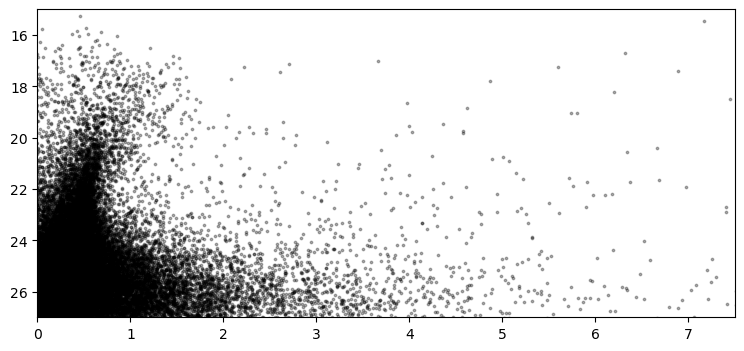

In [4]:
tab = Table.read("hlsp_jades_jwst_nircam_goods-s_photometry_v5.0_catalog.fits", hdu="KRON")
f250 = tab["F250M_KRON"]  # nJy
f444 = tab["F444W_KRON"]  # nJy

# positive fluxes
mask = (f250 > 0) & (f444 > 0)
f250_Jy = f250[mask] * (1e-9)  # Jy
f444_Jy = f444[mask] * (1e-9)  # Jy
print(len(f250_Jy), len(f444_Jy))

# convert to AB mag
m250_ab = -2.5 * np.log10(f250_Jy) + 8.90  # AB mag
m444_ab = -2.5 * np.log10(f444_Jy) + 8.90  # AB mag

# convert to vega mag
m250_vega = -2.5 * np.log10(f250_Jy/271.39)   # vega mag
m444_vega = -2.5 * np.log10(f444_Jy/184.10)  # vega mag
print(len(m250_vega), len(m444_vega))

mask_bright = m444_vega < 30 # restrict F444W mag to brighter than 30 to reduce file size
m444_vega_bright = m444_vega[mask_bright]
m250_vega_bright = m250_vega[mask_bright]
m444_ab_bright = m444_ab[mask_bright]
m250_ab_bright = m250_ab[mask_bright]
#print(np.min(m444_ab_bright), np.max(m444_ab_bright))

color_vega = m250_vega_bright - m444_vega_bright
color_ab = m250_ab_bright - m444_ab_bright
print(len(color_ab), len(m444_ab_bright))

plt.figure(figsize = (9,4))
plt.scatter(color_vega, m444_vega_bright, s = 3, color = 'black', alpha = 0.3)  # vega mag, v5
plt.ylim(27,15)
plt.xlim(0,7.5)
plt.show()


In [5]:
# Stack to determine density
xy = np.vstack([color_vega, m444_vega_bright])
kde = gaussian_kde(xy)
density = kde(xy)

In [6]:
# save to .dat file
output = np.column_stack([color_vega, m444_vega_bright, density])
np.savetxt("jades_cmd_f250m_f444w_kron.dat", output, fmt="%.6f", 
           header="f250m_minus_f444w f444w_apparent cmd_density")